# Demo: from trained networks to Bayesian neural networks

TIF285 *Learning from data*, lecture on Bayesian neural networks.

We return to the regression problem from the ANN demo ($\sin^2 x$, 20 noisy training points on $[0,2]$) and ask what the network model *does not know*. Three ways to fit the same small network:

1. **Standard training, many random starts.** Every start gives a different network. They agree where there is data and disagree outside it, and no single network reports any uncertainty.
2. **Training with a weight regularizer.** Adding $\tfrac12\|\boldsymbol{w}\|^2/\sigma_w^2$ to the loss is the same as putting a Gaussian prior on the weights; the minimum is the MAP estimate. Still a point estimate.
3. **Bayesian inference.** We sample the posterior $p(\boldsymbol{w}|\mathcal{D})$ over all network parameters with `emcee` and propagate the samples to a predictive distribution.

To make step 3 feasible with `emcee`, the network is small: one hidden layer of 10 $\tanh$ nodes, 31 parameters.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import emcee
import logging

logging.getLogger("emcee").setLevel(logging.ERROR)   # silence the 'chain is too short' warning
torch.set_default_dtype(torch.float64)
plt.rcParams.update({"figure.dpi": 100, "font.size": 11})

## 0. Data and network

Same data as in the ANN demo: target $\sin^2 x$, Gaussian noise $\sigma = 0.05$, 20 training and 20 validation points drawn uniformly in $[0, 2]$. Predictions are made on $[-1, 4]$ (data region shaded in the plots).

The network is $1 \to 10 \to 1$ with $\tanh$ hidden nodes and a linear output, $(1+1)\cdot 10 + (10+1)\cdot 1 = 31$ parameters.

In [2]:
def target(x):
    return np.sin(x)**2

rng = np.random.default_rng(2026)
sigma_noise = 0.05
x_tr = rng.uniform(0, 2, 20); y_tr = target(x_tr) + sigma_noise*rng.normal(size=20)
x_va = rng.uniform(0, 2, 20); y_va = target(x_va) + sigma_noise*rng.normal(size=20)
x_grid = np.linspace(-1, 4, 300)

col = lambda a: torch.tensor(a).reshape(-1, 1)    # PyTorch wants (N_data, N_features)
xt, yt, xv, yv, xg = col(x_tr), col(y_tr), col(x_va), col(y_va), col(x_grid)

WIDTH = 10
def make_net():
    return nn.Sequential(nn.Linear(1, WIDTH), nn.Tanh(), nn.Linear(WIDTH, 1))

n_par = sum(p.numel() for p in make_net().parameters())
print("number of parameters:", n_par)

number of parameters: 31


The training loop is the one from the ANN demo, with two changes. The cost is written as $\tfrac12\chi^2$ instead of the MSE: same minimum, but now the cost is minus the log likelihood, which we need in sections 2 and 3. And there is an optional weight penalty, which we switch on in section 2:
$$
C(\boldsymbol{w}) = \frac12 \sum_{i} \frac{\bigl(y(x_i;\boldsymbol{w}) - t_i\bigr)^2}{\sigma^2} \;+\; \frac{1}{2\sigma_w^2}\sum_k w_k^2 .
$$
Here $\boldsymbol{w}$ collects all 31 weights and biases.

In [3]:
def cost(net, sigma_w=None):
    chi2 = (((net(xt) - yt) / sigma_noise)**2).sum()
    C = 0.5 * chi2
    # weight penalty = Gaussian prior on the weights
    if sigma_w is not None: 
        C += 0.5 * sum((p**2).sum() for p in net.parameters()) / sigma_w**2
    return C

def train(net, sigma_w=None, epochs=3000, lr=0.01):
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    for epoch in range(epochs):
        opt.zero_grad()
        C = cost(net, sigma_w)
        C.backward()
        opt.step()
    return net

def predict(net, x=xg):
    with torch.no_grad():
        return net(x).numpy().ravel()

def chi2(net, x, y):
    return (((predict(net, x) - y.numpy().ravel()) / sigma_noise)**2).sum()

def shade(ax):
    ax.axvspan(0, 2, color="0.92", zorder=0)
    ax.plot(x_grid, target(x_grid), "k--", lw=1)
    ax.plot(x_tr, y_tr, "ko", ms=4)
    ax.set(xlabel="$x$", ylim=(-1.2, 2.0))

## 1. Standard training with many random starts

We train ten networks that differ only in the random initialization (the seed).

In [9]:
seeds = range(10)
t0 = time.time()
nets_ml = []
for seed in seeds:
    torch.manual_seed(seed)
    nets_ml.append(train(make_net()))
    print(f"seed {seed}: chi2 train = {chi2(nets_ml[-1], xt, yt):5.1f}\
        chi2 validation = {chi2(nets_ml[-1], xv, yv):5.1f}")
print(f"Total training time: {time.time() - t0:.0f} s")
F_ml = np.array([predict(n) for n in nets_ml])          # (10, len(x_grid))

seed 0: chi2 train =   9.3        chi2 validation =  20.8
seed 1: chi2 train =  10.2        chi2 validation =  21.0
seed 2: chi2 train =   9.6        chi2 validation =  28.8
seed 3: chi2 train =   9.3        chi2 validation =  24.8
seed 4: chi2 train =   9.9        chi2 validation =  20.6
seed 5: chi2 train =   9.5        chi2 validation =  20.4
seed 6: chi2 train =   9.2        chi2 validation =  22.9
seed 7: chi2 train =  10.6        chi2 validation =  24.2
seed 8: chi2 train =   9.1        chi2 validation =  25.5
seed 9: chi2 train =  10.3        chi2 validation =  21.9
Total training time: 3 s


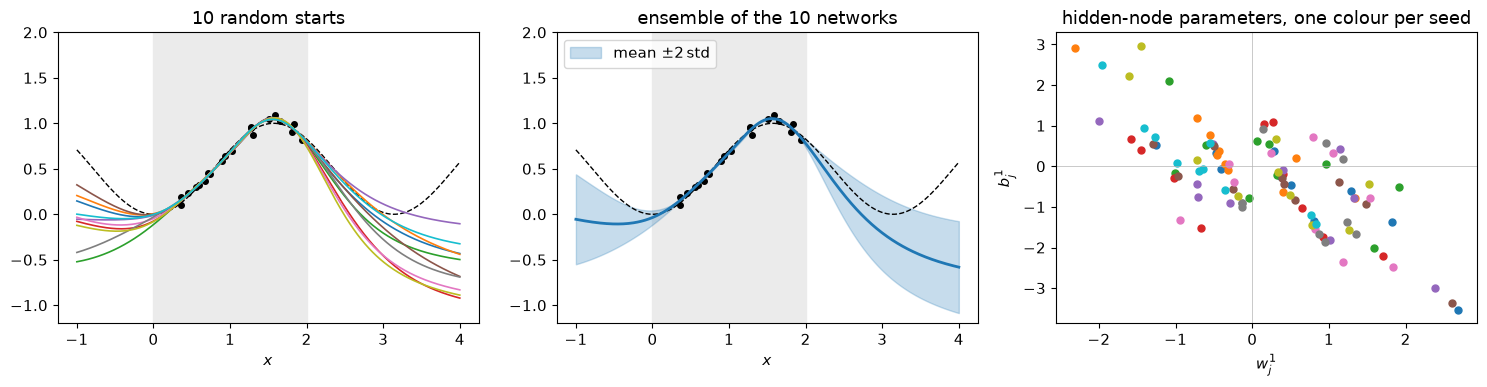

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

# Panel 1
shade(ax[0]); ax[0].plot(x_grid, F_ml.T, lw=1.2)
ax[0].set_title("10 random starts")

# Panel 2
shade(ax[1])
m, s = F_ml.mean(0), F_ml.std(0)
ax[1].fill_between(x_grid, m - 2*s, m + 2*s, color="C0", alpha=0.25, label=r"mean $\pm 2\,$std")
ax[1].plot(x_grid, m, "C0", lw=2)
ax[1].set_title("ensemble of the 10 networks"); ax[1].legend(loc="upper left")

# Panel 3
# hidden-node parameters of each network
for seed, n in zip(seeds, nets_ml):               
    w1, b1 = n[0].weight.detach().numpy().ravel(), n[0].bias.detach().numpy()
    ax[2].plot(w1, b1, "o", ms=5)
ax[2].axhline(0, color="0.7", lw=0.5); ax[2].axvline(0, color="0.7", lw=0.5)
ax[2].set(xlabel="$w^1_j$", ylabel="$b^1_j$", title="hidden-node parameters, one colour per seed")
plt.tight_layout()

Things to note:

- All ten networks fit the training data equally well ($\chi^2_{\rm train}$ below 20, i.e. they even start to fit the noise). Inside $[0,2]$ they are indistinguishable.
- Outside the data they go in all directions. Each single network makes a confident prediction there, with no error bar.
- **Right panel:** the parameters are completely different from seed to seed, even though the functions agree in the data region. Part of this is pure symmetry: permuting the 10 hidden nodes, or flipping the sign of $w^1_j, b^1_j, w^2_j$ together ($\tanh$ is odd), gives the *same* function. Every minimum therefore comes in $10!\cdot 2^{10} \approx 4\times 10^9$ identical copies. The rest is genuine non-identifiability: many different functions fit 20 data points.
- The spread of the ensemble (middle panel) is a crude measure of our ignorance. It is used in practice ("deep ensembles"), but it is not a probability statement: it depends on the number of starts and on the initialization scheme.

## 2. Adding a weight regularizer

Now switch on the penalty $\frac{1}{2\sigma_w^2}\|\boldsymbol{w}\|^2$ (L2 regularization, "weight decay"). Compare with Bayes' theorem, with a Gaussian likelihood and independent Gaussian priors $w_k \sim \mathcal{N}(0, \sigma_w^2)$:
$$
-\ln p(\boldsymbol{w}|\mathcal{D}) = \underbrace{\frac12\chi^2(\boldsymbol{w})}_{-\ln p(\mathcal{D}|\boldsymbol{w})} \;+\; \underbrace{\frac{1}{2\sigma_w^2}\|\boldsymbol{w}\|^2}_{-\ln p(\boldsymbol{w})} \;+\; \text{const} \;=\; C(\boldsymbol{w}) + \text{const}.
$$
**Minimizing the regularized cost is finding the maximum a posteriori (MAP) estimate.** The regularization strength is a prior width. We try $\sigma_w = 1$ and $\sigma_w = 0.3$, again with ten seeds each.

Network with weight regularizer sigma_ws = 1.0
seed 0: chi2 train =  14.3            chi2 validation =  24.7
seed 1: chi2 train =  15.8            chi2 validation =  27.0
seed 2: chi2 train =  13.6            chi2 validation =  24.8
seed 3: chi2 train =  14.4            chi2 validation =  26.9
seed 4: chi2 train =  14.7            chi2 validation =  24.6
seed 5: chi2 train =  15.0            chi2 validation =  26.1
seed 6: chi2 train =  13.8            chi2 validation =  25.1
seed 7: chi2 train =  13.9            chi2 validation =  25.3
seed 8: chi2 train =  14.2            chi2 validation =  25.7
seed 9: chi2 train =  14.8            chi2 validation =  25.7
Network with weight regularizer sigma_ws = 0.3
seed 0: chi2 train =  47.1            chi2 validation =  53.2
seed 1: chi2 train =  46.5            chi2 validation =  54.6
seed 2: chi2 train =  46.7            chi2 validation =  52.8
seed 3: chi2 train =  47.0            chi2 validation =  53.1
seed 4: chi2 train =  45.6            

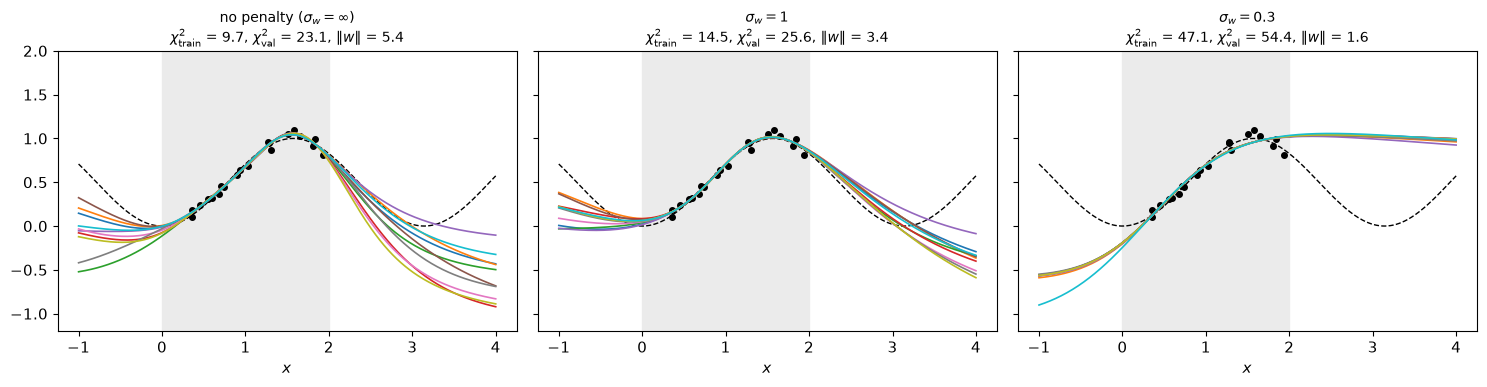

In [16]:
sigma_ws = [1.0, 0.3]
t0 = time.time()
nets_map = {}
for sw in sigma_ws:
    print(f'Network with weight regularizer sigma_ws = {sw}')
    nets_map[sw] = []
    for seed in seeds:
        torch.manual_seed(seed)
        nets_map[sw].append(train(make_net(), sigma_w=sw))
        print(f"seed {seed}: chi2 train = {chi2(nets_map[sw][-1], xt, yt):5.1f}\
            chi2 validation = {chi2(nets_map[sw][-1], xv, yv):5.1f}")
print(f"Total training time: {time.time() - t0:.0f} s")

wnorm = lambda n: torch.cat([p.detach().ravel() for p in n.parameters()]).norm().item()
fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for a, (label, nets) in enumerate([(r"no penalty ($\sigma_w=\infty$)", nets_ml),
                                   (r"$\sigma_w = 1$", nets_map[1.0]),
                                   (r"$\sigma_w = 0.3$", nets_map[0.3])]):
    shade(ax[a])
    ax[a].plot(x_grid, np.array([predict(n) for n in nets]).T, lw=1.2)
    c2 = np.mean([chi2(n, xt, yt) for n in nets]); c2v = np.mean([chi2(n, xv, yv) for n in nets])
    ax[a].set_title(f"{label}\n" + rf"$\chi^2_{{\rm train}}$ = {c2:.1f}, $\chi^2_{{\rm val}}$ = {c2v:.1f}, "
                    + rf"$\|w\|$ = {np.mean([wnorm(n) for n in nets]):.1f}", fontsize=10)
plt.tight_layout()

- The penalty pulls the weights towards zero. With $\sigma_w = 1$ the fit inside the data is still fine, and the extrapolations are somewhat more similar. With $\sigma_w = 0.3$ the network can no longer bend enough: $\chi^2$ rises clearly above the number of data points (underfitting). The prior is too narrow for this function.
- The seeds still give different answers outside the data, since the posterior has many modes (at the least the $4\times10^9$ symmetric copies).
- Above all, **each MAP network is still a single function**. The regularizer has changed which point we pick, not the fact that we pick a point. To get an uncertainty we need the whole posterior.

## 3. Bayesian neural network: sample the posterior with `emcee`

We use the posterior from section 2 with $\sigma_w = 1$:
$$
\ln p(\boldsymbol{w}|\mathcal{D}) = -C(\boldsymbol{w}) + \text{const}.
$$
Our Bayesian neural network is described by this posterior PDF. Each sample corresponds to one parametrization of the neural network. The predictive distribution at a new input $x$ is an average over networks, weighted by the posterior:
$$
p(y^*|x, \mathcal{D}) = \int p(y^*|x,\boldsymbol{w})\, p(\boldsymbol{w}|\mathcal{D})\, d\boldsymbol{w}
\approx \frac{1}{M}\sum_{m=1}^{M} p(y^*|x,\boldsymbol{w}^{(m)}), \qquad \boldsymbol{w}^{(m)} \sim p(\boldsymbol{w}|\mathcal{D}).
$$
So: (1) implement the posterior; (2) draw parameter samples $\boldsymbol{w}^{(m)}$ with MCMC; (3) evaluate the network $y(x;\boldsymbol{w}^{(m)})$ for each, and look at the spread.

`emcee` calls the log posterior for thousands of walker positions, so we write the network as a plain numpy function that evaluates many parameter vectors at once. The parameter vector is ordered $(w^1_1..w^1_{10},\, b^1_1..b^1_{10},\, w^2_1..w^2_{10},\, b^2)$. We first check that it agrees with the PyTorch network and the cost $C$.

In [18]:
sigma_w = 1.0

def unpack(theta):
    # theta has shape (M, 31): one parameter vector per row
    # returns w1, b1, w2, b2
    return theta[:, :WIDTH], theta[:, WIDTH:2*WIDTH], theta[:, 2*WIDTH:3*WIDTH], theta[:, 3*WIDTH]

def net_np(theta, x):
    # Network outputs for M parameter vectors at inputs x; shape (M, len(x)).
    w1, b1, w2, b2 = unpack(np.atleast_2d(theta))
    h = np.tanh(x[None, :, None] * w1[:, None, :] + b1[:, None, :])     # (M, N_x, WIDTH)
    return (h * w2[:, None, :]).sum(-1) + b2[:, None]

def log_posterior(theta):
    r = (net_np(theta, x_tr) - y_tr) / sigma_noise
    return -0.5 * (r**2).sum(1) - 0.5 * (theta**2).sum(1) / sigma_w**2

def flatten(net):
    return torch.cat([p.detach().ravel() for p in net.parameters()]).numpy()

net0 = nets_map[sigma_w][0]
theta_map = flatten(net0)
print("max |net_np - torch| :", np.abs(net_np(theta_map, x_grid)[0] - predict(net0)).max())
print("log posterior, -C    :", log_posterior(theta_map[None])[0], -cost(net0, sigma_w).item())

max |net_np - torch| : 4.440892098500626e-16
log posterior, -C    : -13.0804180849819 -13.080418084981893


### 3a. The prior over functions

Before looking at data: what functions does the prior $w_k \sim \mathcal{N}(0, 1)$ describe? Draw parameter vectors from the prior and plot the networks (compare section 5 of the ANN demo).

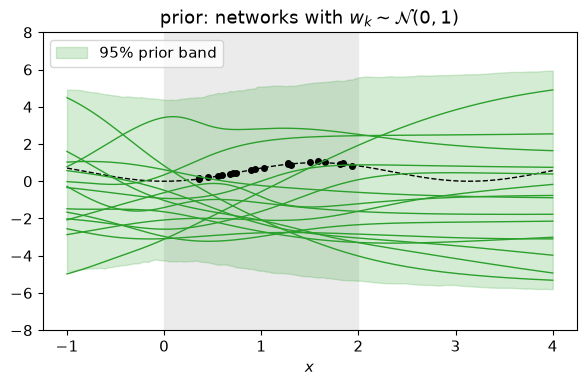

In [21]:
theta_prior = sigma_w * np.random.default_rng(0).normal(size=(4000, n_par))
F_prior = net_np(theta_prior, x_grid)

fig, ax = plt.subplots(figsize=(6, 4))
shade(ax)
ax.fill_between(x_grid, *np.percentile(F_prior, [2.5, 97.5], axis=0), color="C2", alpha=0.2, label="95% prior band")
ax.plot(x_grid, F_prior[:15].T, color="C2", lw=1)
ax.set(title=r"prior: networks with $w_k \sim \mathcal{N}(0, 1)$", ylim=(-8, 8)); ax.legend(loc="upper left")
plt.tight_layout()

### 3b. Sampling

- **Walkers:** `emcee` needs at least $2 \times 31$; we use 64.
- **Start:** a small ball around the MAP network from section 2. Starting from random prior draws also works but needs a much longer burn-in.
- **Thinning:** the chain is strongly correlated, so we store only every 50th step.

The run takes about half a minute on a laptop.

In [22]:
n_walkers, n_steps, thin = 64, 150_000, 100

def run_emcee(theta_start, seed):
    rs = np.random.default_rng(seed)
    p0 = theta_start + 1e-2 * rs.normal(size=(n_walkers, n_par))
    sampler = emcee.EnsembleSampler(n_walkers, n_par, log_posterior, vectorize=True)
    sampler.run_mcmc(p0, n_steps // thin, thin_by=thin, progress=False)
    return sampler

t0 = time.time()
sampler = run_emcee(theta_map, seed=1)
print(f"sampling time: {time.time() - t0:.0f} s")
print(f"acceptance fraction: {sampler.acceptance_fraction.mean():.3f}")
tau = sampler.get_autocorr_time(quiet=True) * thin
print(f"autocorrelation time: {tau.mean():.0f} steps (estimate, likely a lower bound)")

sampling time: 30 s
acceptance fraction: 0.015
autocorrelation time: 15400 steps (estimate, likely a lower bound)


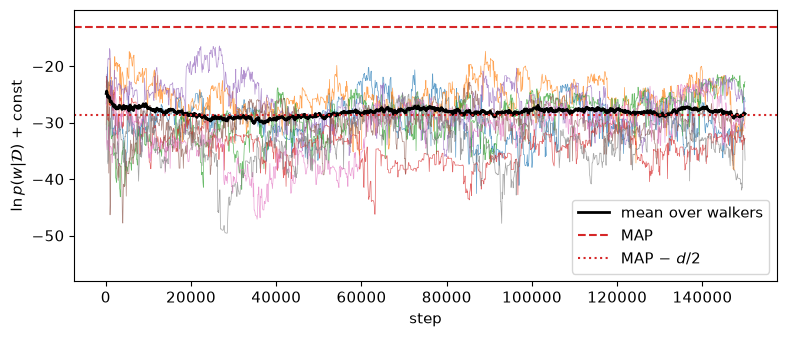

In [23]:
lp = sampler.get_log_prob()                     # (stored steps, walkers)
steps = thin * np.arange(1, lp.shape[0] + 1)
lp_map = log_posterior(theta_map[None])[0]

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(steps, lp[:, :8], lw=0.5, alpha=0.7)
ax.plot(steps, lp.mean(1), "k", lw=2, label="mean over walkers")
ax.axhline(lp_map, color="C3", ls="--", label="MAP")
ax.axhline(lp_map - n_par/2, color="C3", ls=":", label=r"MAP $-\ d/2$")
ax.set(xlabel="step", ylabel=r"$\ln p(w|\mathcal{D})$ + const", ylim=(lp_map - 45, lp_map + 3))
ax.legend(loc="lower right"); plt.tight_layout()

- The walkers start at the MAP and *drop* in log posterior within the first few thousand steps. This is not a failure: in $d = 31$ dimensions almost all the posterior probability lies away from the peak. For a Gaussian posterior, $-2\ln p$ follows a $\chi^2_d$ distribution, so the typical log posterior is about $d/2 \approx 15$ below the maximum (dotted line).
- The acceptance fraction is about 1% and the autocorrelation time is of order $10^4$ steps. The stretch move of `emcee` struggles with the elongated, curved, multimodal posterior of a neural network. Even 31 parameters is a hard sampling problem.

In [25]:
burn = lp.shape[0] // 3                                         # discard the first third
chain = sampler.get_chain(discard=burn, flat=True)
print("posterior samples kept:", chain.shape[0])
# network outputs y(x; w^(m))
F_bnn = net_np(chain[::5], x_grid)                              
# add noise: p(y*|x,D)
Y_bnn = F_bnn + sigma_noise * np.random.default_rng(1).normal(size=F_bnn.shape)   

posterior samples kept: 64000


### 3c. The posterior predictive distribution

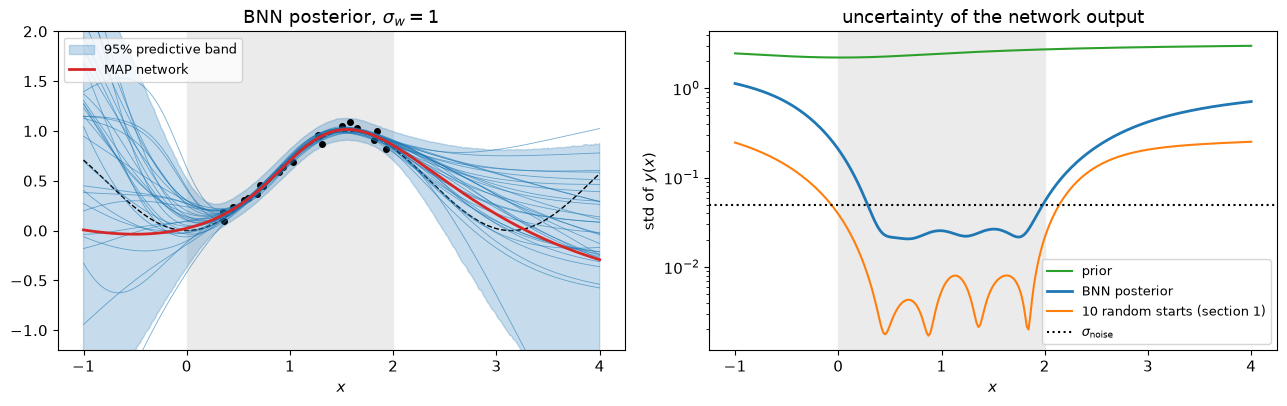

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
shade(ax[0])
ax[0].fill_between(x_grid, *np.percentile(Y_bnn, [2.5, 97.5], axis=0), color="C0", alpha=0.25, label="95% predictive band")
#ax[0].fill_between(x_grid, *np.percentile(F_bnn, [16, 84], axis=0), color="C0", alpha=0.35, label="68% band of $y(x;w)$")
ax[0].plot(x_grid, F_bnn[::400].T, color="C0", lw=0.6, alpha=0.6)
ax[0].plot(x_grid, predict(net0), "C3", lw=2, label="MAP network")
ax[0].set_title(r"BNN posterior, $\sigma_w = 1$"); ax[0].legend(loc="upper left", fontsize=9)

ax[1].semilogy(x_grid, F_prior.std(0), "C2", label="prior")
ax[1].semilogy(x_grid, F_bnn.std(0), "C0", lw=2, label="BNN posterior")
ax[1].semilogy(x_grid, F_ml.std(0), "C1", label="10 random starts (section 1)")
ax[1].axhline(sigma_noise, color="k", ls=":", label=r"$\sigma_{\rm noise}$")
ax[1].axvspan(0, 2, color="0.92", zorder=0)
ax[1].set(xlabel="$x$", ylabel="std of $y(x)$", title="uncertainty of the network output"); ax[1].legend(fontsize=9)
plt.tight_layout()

- **Inside the data** the posterior networks agree to about $0.02$, below the noise $\sigma = 0.05$: 20 data points pin the function down. The predictive band there is dominated by the noise term.
- **Outside the data** the uncertainty grows by more than an order of magnitude towards the ends of the plotted range. It stays below the prior width (right panel): the data still fix the value and slope at the edges, and smooth $\tanh$ networks cannot turn arbitrarily fast. The true function lies inside the 95% band, while the MAP network alone would have been confidently wrong at $x = 4$.
- The spread of the 10 random starts (orange) has a similar *shape* but is 3–10 times smaller everywhere, and has no probabilistic meaning: it would change with the number of starts and the initialization scheme. The MAP networks of section 2 agree with each other even better than that, which shows that agreement between optimized networks is not a measure of uncertainty.
- How far the band opens outside the data is set by the prior. A different $\sigma_w$, or a different activation function, gives a different extrapolation (compare the ReLU vs tanh panels in the ANN demo).

### 3d. Is the sampling converged? Run it again

A second, independent run, started from a different MAP network (seed 1 in section 2).

sampling time: 31 s


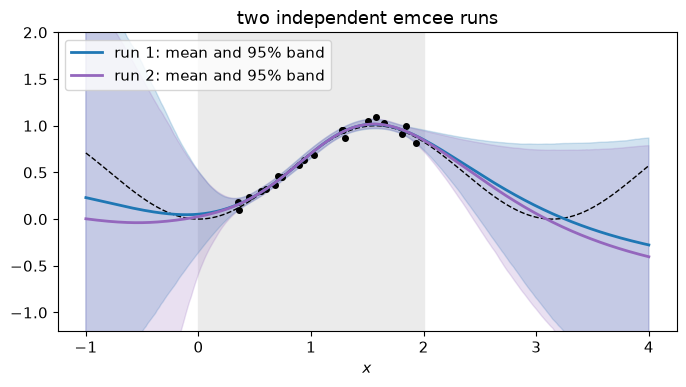

In [27]:
t0 = time.time()
sampler2 = run_emcee(flatten(nets_map[sigma_w][1]), seed=2)
print(f"sampling time: {time.time() - t0:.0f} s")
F_bnn2 = net_np(sampler2.get_chain(discard=burn, flat=True)[::5], x_grid)

fig, ax = plt.subplots(figsize=(7, 4))
shade(ax)
for F, c, lab in [(F_bnn, "C0", "run 1"), (F_bnn2, "C4", "run 2")]:
    lo, hi = np.percentile(F, [2.5, 97.5], axis=0)
    ax.fill_between(x_grid, lo, hi, color=c, alpha=0.2)
    ax.plot(x_grid, F.mean(0), c, lw=2, label=f"{lab}: mean and 95% band")
ax.legend(loc="upper left"); ax.set_title("two independent emcee runs")
plt.tight_layout()

The two runs agree inside the data and on the overall width of the band. Far outside the data the details (where the mean goes, the exact width) differ: the chains have not fully explored the posterior. With $\tau \sim 10^4$ steps, a run of $1.5\times 10^5$ steps gives only of order ten independent samples per walker.

**Take-home.**

- A neural network trained by minimizing a cost is a point estimate. Random starts reveal that many very different parameter vectors (and functions) fit the data.
- An L2 regularizer is a Gaussian prior on the weights, and regularized training gives the MAP estimate.
- A Bayesian neural network keeps the whole posterior $p(\boldsymbol{w}|\mathcal{D})$ and averages predictions over it. The uncertainty is small where there is data and reverts to the prior where there is none.
- Sampling the weight posterior is hard: `emcee` already struggles with 31 parameters. Real networks have $10^4$–$10^9$ parameters. In practice one uses gradient-based samplers (Hamiltonian Monte Carlo) for small networks, and **variational inference** (Bayes by Backprop) or ensembles for large ones.